In [6]:
import numpy as np
import scipy.linalg as la
from scipy.linalg import eig, qr, block_diag
from numpy.linalg import svd
from scipy.linalg import null_space
import math
import matplotlib.pyplot as plt
from numpy.linalg import qr, norm
from scipy.linalg import solve_discrete_are, solve_discrete_lyapunov, block_diag
import random


def grad_true(Sigma_0,A,B,Q,R,K):
    dx = A.shape[0]
    PK = solve_discrete_lyapunov((A-B@K).T,Q+K.T@R@K)
    EK = (R + B.T@PK@B)@K - B.T@PK@A
    Sigma_K = solve_discrete_lyapunov(A-B@K,Sigma_0)
    grad = 2*EK@Sigma_K
    return grad


def grad_avg_true(As,Bs,Qs,Rs,K,Sigma_0,gamma_h):
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    H = len(As)
    grad_avg = np.zeros((du,dx))
    for i in range(H):
        grad_cost_i = grad_true(Sigma_0,np.sqrt(gamma_h[i])*As[i],np.sqrt(gamma_h[i])*Bs[i],Qs[i],Rs[i],K)
        grad_avg += (1/H)*grad_cost_i
    return grad_avg


def zo2p(A, B, Q, R, K, r, ns, gamma):
    dx = A.shape[0]
    du = B.shape[1]
    K1 = []
    K2 = []
    cost_1 = []
    cost_2 = []
    grad = np.zeros((du, dx))
    Ul=[]
    for l in range(ns):
        U = np.random.randn(B.shape[1], A.shape[0])
        U = (U / np.linalg.norm(U))

        K1.append(K + r*U)
        K2.append(K - r*U)

        # Compute cost
        x_0 = np.random.normal(0, 1, size=(1,dx))[0]   
        cost_1.append(cost_gamma_x0(A, B, Q, R, K1[-1],gamma,x_0))
        cost_2.append(cost_gamma_x0(A, B, Q, R, K2[-1],gamma,x_0))
        Ul.append(U)

        #grad += ((dx * du) / (2 * ns * (r))) * (cost_1[l] - cost_2[l]) * Ul[l]
        grad += ((dx * du) / ( ns * (r**2))) * (cost_1[l]) * Ul[l] #one point estimation


    return grad


def cost_gamma(A, B, Q, R, K, gamma, ns_cost):
        dx = A.shape[0]
        tau = 50
        cost = 0
        rng = np.random.default_rng()
        for i in range(ns_cost):
            cost_i = 0
            x = np.random.normal(0, 1, size=(1,dx))[0]
            for t in range(tau):
                u = -K@x
                cost_i += (gamma**t)*(x.T@Q@x + u.T@R@u)
                w = rng.normal(loc=0.0, scale=0.1, size=dx)
                x = (A - B @ K) @ x + w
            cost+=(1/ns_cost)*cost_i  
        
        return cost
    
def cost_gamma_avg(As, Bs, Qs, Rs, K, gamma, ns_cost):
    
    cost_avg = 0
    H = len(As)
    for h in range(H):
        cost_avg+=(1/H)*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma, ns_cost)
    
    return cost_avg


def cost_gamma_x0(A, B, Q, R, K, gamma, x):
        dx = A.shape[0]
        rng = np.random.default_rng()
        tau = 50
        cost = 0
        for t in range(tau):
            u = -K@x
            cost += (gamma**t)*(x.T@Q@x + u.T@R@u)
            w = rng.normal(loc=0.0, scale=0.1, size=dx)
            x = (A - B @ K) @ x + w
        return cost

    
def lqr_cost_K(Sigma_0,A,B,Q,R,K,gamma):
        PK = solve_discrete_lyapunov(np.sqrt(gamma)*(A-B@K).T,Q+K.T@R@K)
        return np.trace(Sigma_0@PK)
    
    
def lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma):
        cost_avg = 0
        H = len(As)
        for h in range(H):
            cost_avg+=(1/H)*lqr_cost_K(Sigma_0,As[h],Bs[h],Qs[h],Rs[h],K,gamma)
        return cost_avg
    
def gradient_avg_zo2p(As, Bs, Qs, Rs, K, r, ns, gamma_h):
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    H = len(As)
    grad_avg = np.zeros((du,dx))
    
    for h in range(H):
        grad_avg += (1/H)*zo2p(As[h], Bs[h], Qs[h], Rs[h], K, r, ns, gamma_h[h])
    
    return grad_avg


def spectral_radius_mt(As,Bs,K):
    
    H = len(As)
    srs = []
    for h in range(H):
        srs.append(max(abs(la.eigvals(As[h]-Bs[h]@K))))
    
    return srs


def spectral_radius_mt_gamma(As,Bs,K,gamma):
    
    H = len(As)
    srs = []
    for h in range(H):
        srs.append(max(abs(la.eigvals(np.sqrt(gamma)*As[h]-np.sqrt(gamma)*Bs[h]@K))))
    
    return srs



def state_norm(As, Bs, K, tau, gamma, x_bound, x0=None):

    dx = As[0].shape[0]
    flag = 1
    if x0 is None:
        x0 = np.random.randn(dx)
        x0 = x0 / np.linalg.norm(x0)
    H = len(As)
    for h in range(H):    
        
        F = np.sqrt(gamma)*(As[h] - Bs[h] @ K)

        F_tau = np.linalg.matrix_power(F, tau)

        x_tau = F_tau @ x0
        
        if np.linalg.norm(x_tau) >= x_bound:
            flag = 0
            break
    return flag


    
def find_stabilizing_hd(As,Bs,Qs,Rs,gamma,N,r,ns,eta,xi,ns_cost):
    
    H = len(As)
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    K = np.zeros((du,dx))
    sr = []
    Sigma_0 = np.eye(dx)
    
    gammas = []
    
    gamma_h = [gamma]*H
    
    sr.append(spectral_radius_mt(As,Bs,K))
    flag = 0
    
    Ks = [K.copy()]
    check_lyap = 1
    j=0
    error_grads_norm = []
    while flag == 0:
        
        
        gammas.append(gamma_h.copy())
        
        print(f"Iteration: {j}, Spectral radius: {sr[-1][0]}, gamma: {min(gammas[-1])}")
        K_l = K
        error_grads_norm.append(la.norm(gradient_avg_zo2p(As, Bs, Qs, Rs, K.copy(), r, ns, gamma_h) - grad_avg_true(As,Bs,Qs,Rs,K_l,Sigma_0,gamma_h)))
        print(error_grads_norm[-1])
        for n in range(N):
            grad_avg = gradient_avg_zo2p(As, Bs, Qs, Rs, K_l, r, ns, gamma_h)
            K_l=K_l - eta*grad_avg
        K = K_l
        
        print("-----")
        print(f"cost: {lqr_cost_K(Sigma_0,As[0],Bs[0],Qs[0],Rs[0],K,gamma_h[0])}")
        print("-----")
       
        
        #Update the discount factor
        alphas = []
        for h in range(H):
            sigma_min_h = min(abs(la.eigvals(Qs[h] + K.T@Rs[h]@K)))
            alpha_h = sigma_min_h/(2*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma_h[h],ns_cost) - sigma_min_h)
            #alpha_h = sigma_min_h/(2*lqr_cost_K(Sigma_0,As[h],Bs[h],Qs[h],Rs[h],K,gamma_h[h]) - sigma_min_h)
            alphas.append(alpha_h)
            
           
        print("-----")
        print(f"min alpha ={min(alphas)}, avg alpha = {np.mean(alphas)}")
        print("-----")
        
         
        
        gamma_h_min = [(1+xi*min(alphas))*gamma_h[0]]*H
        gamma_h = gamma_h_min.copy()
        
    
        Ks.append(K.copy)
        sr.append(spectral_radius_mt(As,Bs,K))  
        
        if gamma_h[0]>=1: 
            flag = 1
            gammas.append(gamma_h.copy())
            break
        
        j+=1
        
    return K, sr, gammas, Ks, error_grads_norm


def is_positive_definite_eig(A, tol=1e-8):
    if not np.allclose(A, A.T):
        print("Warning: Matrix is not symmetric. Eigenvalue test alone is not sufficient.")
        return False
        
    eigenvalues = np.linalg.eigvalsh(A)
    
    # Check if all eigenvalues are greater than a small tolerance
    return np.all(eigenvalues > tol)


def verify_gamma(K,As,Bs,Qs,Rs,gamma,gamma_plus):
    
    flag = 1
    for h in range(len(As)):
        PK_h = solve_discrete_lyapunov(np.sqrt(gamma)*(As[h]-Bs[h]@K).T,Qs[h]+K.T@Rs[h]@K)
        
        M = PK_h - (gamma_plus/gamma)*(PK_h - (Qs[h]+K.T@Rs[h]@K)) 
        
        if is_positive_definite_eig(M) == False:
            flag = 0
    
    return flag




def update_gamma(gamma, As, Bs, Qs, Rs, K, Sigma_0):
        C_old = lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma)
        gamma_lb = gamma
        gamma_ub = 1.0
        
        # bisection
        while gamma_ub - gamma_lb > 1e-4:
            gamma_mid = (gamma_ub + gamma_lb)/2
            C_new = lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma_mid)

            if C_new < 2.5*C_old:
                    gamma_lb = gamma_mid
            elif C_new > 4*C_old:
                    gamma_ub = gamma_mid
            else:
                    gamma_lb = gamma_mid
                    break
        print(gamma_lb)
        return gamma_lb

$\textbf{LTI system (Inverted Pendulum)}$

In [7]:
l = 1 
d0 = 2
du = 1

dt = 0.25
g = 9.81

H = 1000
dx = 20


As = []
Bs = []
Qs = []
Rs = []
ms = []
ells =[]
for h in range(H):
    #m = random.uniform(0.5, 0.75)
    m = 0.5 + random.uniform(0.05, 0.2)
    ms.append(m)
    #ell = random.uniform(1.15, 1.25)
    ell = 0.75 + random.uniform(0.05, 0.2)
    ells.append(ell)
    A0 = np.array([ [1, dt], [(g/ell)*dt, 1]])
    B0 = np.array([  [0],  [dt/(m*(ell**2))]])
    
    As.append(A0)
    Bs.append(B0)
    Qs.append(np.eye(d0))
    Rs.append(np.eye(du))

$\textbf{Parameters:}$

In [8]:
gamma = 0.2
ns = 5
r = 0.1
N = 3
xi = 0.5
ns_cost = 50

$\textbf{Single Task:}$

In [9]:
eta = 1e-6

As_single = [As[0]]
Bs_single = [Bs[0]]
Qs_single = [Qs[0]]
Rs_single = [Rs[0]]
K_single,srs_singletask,gammas_singletask,Ks_single, error_grads_norm = find_stabilizing_hd(As_single,Bs_single,Qs_single,Rs_single,gamma,N,r,ns,eta,xi,ns_cost)

Iteration: 0, Spectral radius: 1.8492883090503027, gamma: 0.2
796.7535655360547
-----
cost: 9.105130656662492
-----
-----
min alpha =0.058871382978388884, avg alpha = 0.058871382978388884
-----
Iteration: 1, Spectral radius: 1.849300901251247, gamma: 0.2058871382978389
1344.420299583966
-----
cost: 9.82884277463286
-----
-----
min alpha =0.04869237395195988, avg alpha = 0.04869237395195988
-----
Iteration: 2, Spectral radius: 1.8491816849674372, gamma: 0.21089970506278752
1243.7030182630233
-----
cost: 10.528629912036083
-----
-----
min alpha =0.059181780924368065, avg alpha = 0.059181780924368065
-----
Iteration: 3, Spectral radius: 1.8491174091256126, gamma: 0.21714041513380739
1428.5534955937362
-----
cost: 11.53398545206986
-----
-----
min alpha =0.045377170811366566, avg alpha = 0.045377170811366566
-----
Iteration: 4, Spectral radius: 1.8491775793214, gamma: 0.2220670239875963
2797.985936222093
-----
cost: 12.465710416357876
-----
-----
min alpha =0.053373821508591324, avg alpha 

25720.946473887434
-----
cost: 93.95651414545404
-----
-----
min alpha =0.006666947079710455, avg alpha = 0.006666947079710455
-----
Iteration: 44, Spectral radius: 1.7856144072544753, gamma: 0.3030738278524763
64519.671660567736
-----
cost: 62.98081898386854
-----
-----
min alpha =0.0070824116208145615, avg alpha = 0.0070824116208145615
-----
Iteration: 45, Spectral radius: 1.7645834745138504, gamma: 0.3041470746526498
7161.191783961724
-----
cost: 67.45365846768279
-----
-----
min alpha =0.006941125732811812, avg alpha = 0.006941125732811812
-----
Iteration: 46, Spectral radius: 1.7648119570409593, gamma: 0.3052026361958653
3792.9737320529675
-----
cost: 76.88014511322494
-----
-----
min alpha =0.007182262993250579, avg alpha = 0.007182262993250579
-----
Iteration: 47, Spectral radius: 1.7680818263587974, gamma: 0.30629865899556136
24879.25150165637
-----
cost: 67.4608732270322
-----
-----
min alpha =0.009583091273315362, avg alpha = 0.009583091273315362
-----
Iteration: 48, Spectral

-----
min alpha =0.007338206193268676, avg alpha = 0.007338206193268676
-----
Iteration: 87, Spectral radius: 1.6604296240494163, gamma: 0.34821077703666764
3071.2794021954915
-----
cost: 121.38670417504942
-----
-----
min alpha =0.005224722018064706, avg alpha = 0.005224722018064706
-----
Iteration: 88, Spectral radius: 1.6607657872542099, gamma: 0.34912042929352305
8588.304083265646
-----
cost: 132.56574497973418
-----
-----
min alpha =0.0051204441818778436, avg alpha = 0.0051204441818778436
-----
Iteration: 89, Spectral radius: 1.6615044016358764, gamma: 0.35001425512899836
7968.514062121697
-----
cost: 153.65267560233553
-----
-----
min alpha =0.0047331424104920345, avg alpha = 0.0047331424104920345
-----
Iteration: 90, Spectral radius: 1.6639152437995857, gamma: 0.3508425887866123
6806.5601120001575
-----
cost: 140.06432015770295
-----
-----
min alpha =0.004169563778970358, avg alpha = 0.004169563778970358
-----
Iteration: 91, Spectral radius: 1.6588592077959834, gamma: 0.35157401

-----
min alpha =0.006058839512649974, avg alpha = 0.006058839512649974
-----
Iteration: 133, Spectral radius: 1.5351901217989532, gamma: 0.3931504821631035
1557.8583614944632
-----
cost: 103.00120147240904
-----
-----
min alpha =0.005436922578759992, avg alpha = 0.005436922578759992
-----
Iteration: 134, Spectral radius: 1.5304230720348135, gamma: 0.394219246529765
15333.75031885531
-----
cost: 110.94433642959672
-----
-----
min alpha =0.004271021965075211, avg alpha = 0.004271021965075211
-----
Iteration: 135, Spectral radius: 1.5338410265404763, gamma: 0.395061106060257
15680.408864409439
-----
cost: 112.69338735627247
-----
-----
min alpha =0.004064280213207563, avg alpha = 0.004064280213207563
-----
Iteration: 136, Spectral radius: 1.5324070432390267, gamma: 0.3958639255784413
23808.186707578894
-----
cost: 119.22096321796612
-----
-----
min alpha =0.0033090077874831265, avg alpha = 0.0033090077874831265
-----
Iteration: 137, Spectral radius: 1.5346203373988887, gamma: 0.396518883

-----
cost: 134.76912394876035
-----
-----
min alpha =0.0042813526112003494, avg alpha = 0.0042813526112003494
-----
Iteration: 180, Spectral radius: 1.4681605294283737, gamma: 0.4281590559216397
23910.469273998915
-----
cost: 141.43620659649267
-----
-----
min alpha =0.0038854736745209, avg alpha = 0.0038854736745209
-----
Iteration: 181, Spectral radius: 1.4699008470849364, gamma: 0.42899085629178535
29967.643444693902
-----
cost: 129.31259539839073
-----
-----
min alpha =0.0024823449942143415, avg alpha = 0.0024823449942143415
-----
Iteration: 182, Spectral radius: 1.4603177963625993, gamma: 0.42952330794412513
4565.643734206553
-----
cost: 131.01014454012164
-----
-----
min alpha =0.0026196082815036752, avg alpha = 0.0026196082815036752
-----
Iteration: 183, Spectral radius: 1.460366339492439, gamma: 0.4300858993514197
7784.682348162175
-----
cost: 133.97387779620954
-----
-----
min alpha =0.003170928219072922, avg alpha = 0.003170928219072922
-----
Iteration: 184, Spectral radius:

-----
cost: 163.41692485660252
-----
-----
min alpha =0.003829219894245531, avg alpha = 0.003829219894245531
-----
Iteration: 227, Spectral radius: 1.4101708642166884, gamma: 0.4639891914417139
22960.64074268319
-----
cost: 161.39116617008287
-----
-----
min alpha =0.0029191160760080655, avg alpha = 0.0029191160760080655
-----
Iteration: 228, Spectral radius: 1.407185147688446, gamma: 0.4646664105956297
12225.245303277858
-----
cost: 152.15237162682052
-----
-----
min alpha =0.004469597882560358, avg alpha = 0.004469597882560358
-----
Iteration: 229, Spectral radius: 1.401074502962686, gamma: 0.4657048465980772
30532.64771567135
-----
cost: 142.65930034463528
-----
-----
min alpha =0.003839322234836952, avg alpha = 0.003839322234836952
-----
Iteration: 230, Spectral radius: 1.3924882371632035, gamma: 0.4665988420842848
17573.816058199485
-----
cost: 152.7189226143968
-----
-----
min alpha =0.0023214199692228226, avg alpha = 0.0023214199692228226
-----
Iteration: 231, Spectral radius: 1

... (9 outputs left out)

-----
cost: 233.83491423961308
-----
-----
min alpha =0.0019833772107201364, avg alpha = 0.0019833772107201364
-----
Iteration: 690, Spectral radius: 1.0062950566139557, gamma: 0.835720116902535
24696.97390517092
-----
cost: 214.8915283257269
-----
-----
min alpha =0.0018902059649427909, avg alpha = 0.0018902059649427909
-----
Iteration: 691, Spectral radius: 0.9951935713848648, gamma: 0.836509958477531
19989.24386917434
-----
cost: 207.64382786703175
-----
-----
min alpha =0.0021661939816940996, avg alpha = 0.0021661939816940996
-----
Iteration: 692, Spectral radius: 0.9909531680146126, gamma: 0.8374159798963716
45613.64664410376
-----
cost: 203.737005495922
-----
-----
min alpha =0.0033607476736571807, avg alpha = 0.0033607476736571807
-----
Iteration: 693, Spectral radius: 0.9881397665094955, gamma: 0.8388231517995316
58615.905423185446
-----
cost: 204.1928392015137
-----
-----
min alpha =0.0019139300689832567, avg alpha = 0.0019139300689832567
-----
Iteration: 694, Spectral radius:

26601.685852633957
-----
cost: 207.1743831387116
-----
-----
min alpha =0.0023651470626438725, avg alpha = 0.0023651470626438725
-----
Iteration: 736, Spectral radius: 0.9607417263860198, gamma: 0.8842895014467551
32021.644032290264
-----
cost: 212.14801681597842
-----
-----
min alpha =0.0021455105190724333, avg alpha = 0.0021455105190724333
-----
Iteration: 737, Spectral radius: 0.9629009802929271, gamma: 0.8852381276603848
21618.388446953933
-----
cost: 210.44212466832505
-----
-----
min alpha =0.0020250999108717463, avg alpha = 0.0020250999108717463
-----
Iteration: 738, Spectral radius: 0.9612116539680995, gamma: 0.8861344754870975
11173.746265653172
-----
cost: 201.68922254886155
-----
-----
min alpha =0.0023254266807579004, avg alpha = 0.0023254266807579004
-----
Iteration: 739, Spectral radius: 0.9550065516344197, gamma: 0.8871647958631159
37744.86268478827
-----
cost: 200.92933234168063
-----
-----
min alpha =0.0017657090079098358, avg alpha = 0.0017657090079098358
-----
Iterat

-----
cost: 211.1348342372708
-----
-----
min alpha =0.0025900888116458134, avg alpha = 0.0025900888116458134
-----
Iteration: 782, Spectral radius: 0.9330584981711547, gamma: 0.9301504870474792
34337.26869372195
-----
cost: 214.60847879867134
-----
-----
min alpha =0.002375909419499705, avg alpha = 0.002375909419499705
-----
Iteration: 783, Spectral radius: 0.9340782394522487, gamma: 0.9312554636993432
23183.091666080552
-----
cost: 210.81577892739182
-----
-----
min alpha =0.0016106617475478342, avg alpha = 0.0016106617475478342
-----
Iteration: 784, Spectral radius: 0.9310376187633775, gamma: 0.932005432475631
28056.026928384174
-----
cost: 216.50637419849951
-----
-----
min alpha =0.0018607496298479887, avg alpha = 0.0018607496298479887
-----
Iteration: 785, Spectral radius: 0.9343577194641457, gamma: 0.9328725468573787
15029.689660447286
-----
cost: 225.5840218874732
-----
-----
min alpha =0.002164737206029787, avg alpha = 0.002164737206029787
-----
Iteration: 786, Spectral radius

-----
cost: 210.1092719630127
-----
-----
min alpha =0.0015060149534425805, avg alpha = 0.0015060149534425805
-----
Iteration: 828, Spectral radius: 0.909143313524585, gamma: 0.9751868835526443
44827.64324410908
-----
cost: 209.98755777927278
-----
-----
min alpha =0.0017270635835389774, avg alpha = 0.0017270635835389774
-----
Iteration: 829, Spectral radius: 0.9086008147776738, gamma: 0.9760289884295087
52582.419183229955
-----
cost: 223.2023291098971
-----
-----
min alpha =0.0013352821156885377, avg alpha = 0.0013352821156885377
-----
Iteration: 830, Spectral radius: 0.9162669279351878, gamma: 0.9766806254558305
34964.986367640675
-----
cost: 221.75204480329916
-----
-----
min alpha =0.0015170659920080124, avg alpha = 0.0015170659920080124
-----
Iteration: 831, Spectral radius: 0.9149377080750696, gamma: 0.9774214699367966
12707.767594004168
-----
cost: 212.80612008317866
-----
-----
min alpha =0.001751622418626605, avg alpha = 0.001751622418626605
-----
Iteration: 832, Spectral radi

$\textbf{Estimation error:}$

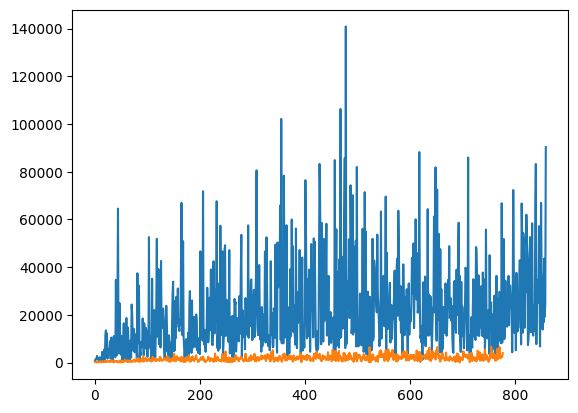

In [13]:
plt.plot(error_grads_norm)
plt.plot(error_grad_norm4)

$\textbf{Multitask:}$

$H=50$

In [10]:
H_tasks = 50
eta = 2.5e-5

indices = random.sample(range(1, H), H_tasks-1)

As_tasks = [As[0]]
Bs_tasks = [Bs[0]]
Qs_tasks = [Qs[0]]
Rs_tasks = [Rs[0]]
for h in range(len(indices)):
    As_tasks.append(As[indices[h]])
    Bs_tasks.append(Bs[indices[h]])
    Qs_tasks.append(Qs[indices[h]])
    Rs_tasks.append(Rs[indices[h]])

K_H50,srs_multitask_H50,gammas_multitask_H50, Ks_H50, error_grad_norm4 = find_stabilizing_hd(As_tasks,Bs_tasks,Qs_tasks,Rs_tasks,gamma,N,r,ns,eta,xi, ns_cost)

Iteration: 0, Spectral radius: 1.8492883090503027, gamma: 0.2
299.7504108244396
-----
cost: 9.070299016890175
-----
-----
min alpha =0.030374767608914263, avg alpha = 0.06403346241087822
-----
Iteration: 1, Spectral radius: 1.8479358007205249, gamma: 0.20303747676089146
84.18407321853213
-----
cost: 9.310906886685842
-----
-----
min alpha =0.041395504514196046, avg alpha = 0.064790012642973
-----
Iteration: 2, Spectral radius: 1.843424159778186, gamma: 0.2072398961537947
245.15770859242178
-----
cost: 9.820089072578202
-----
-----
min alpha =0.03055612217285356, avg alpha = 0.05986552227190695
-----
Iteration: 3, Spectral radius: 1.8418680916489825, gamma: 0.2104061199467771
144.84857315632595
-----
cost: 10.255489392661831
-----
-----
min alpha =0.0307260975720843, avg alpha = 0.0547832141009156
-----
Iteration: 4, Spectral radius: 1.8422371210970327, gamma: 0.21363859943240127
307.4766880258342
-----
cost: 10.713888747171325
-----
-----
min alpha =0.03299076189089073, avg alpha = 0.0

-----
cost: 30.009616330606693
-----
-----
min alpha =0.011471420574175844, avg alpha = 0.019562625179029573
-----
Iteration: 40, Spectral radius: 1.7124593238536505, gamma: 0.29728477325736885
348.8837649643028
-----
cost: 31.771917933211313
-----
-----
min alpha =0.010024365478088717, avg alpha = 0.01908781891703668
-----
Iteration: 41, Spectral radius: 1.7159018831669721, gamma: 0.29877481886647017
388.133269318778
-----
cost: 31.745266433394693
-----
-----
min alpha =0.009626686452780083, avg alpha = 0.01906325180442693
-----
Iteration: 42, Spectral radius: 1.709197258360608, gamma: 0.300212924617077
652.5533343270419
-----
cost: 32.16491572751224
-----
-----
min alpha =0.010902694071980513, avg alpha = 0.019670089932617797
-----
Iteration: 43, Spectral radius: 1.7052226011052434, gamma: 0.30184948945385426
635.0224782753181
-----
cost: 32.68612278173807
-----
-----
min alpha =0.00957687151076591, avg alpha = 0.018845816245648805
-----
Iteration: 44, Spectral radius: 1.700141807303

-----
cost: 49.89676574077659
-----
-----
min alpha =0.006303662542229916, avg alpha = 0.012546399735182068
-----
Iteration: 79, Spectral radius: 1.5599447861824194, gamma: 0.35389134368893616
818.3823632412036
-----
cost: 49.18238420464846
-----
-----
min alpha =0.00668414175836437, avg alpha = 0.012694085267366834
-----
Iteration: 80, Spectral radius: 1.5512327758389763, gamma: 0.35507407364307364
1835.2419367031844
-----
cost: 49.33511495322833
-----
-----
min alpha =0.008485586666420141, avg alpha = 0.012413969938881997
-----
Iteration: 81, Spectral radius: 1.5459616627180823, gamma: 0.35658057955552225
697.7918540577624
-----
cost: 49.45589991939209
-----
-----
min alpha =0.008015521575920012, avg alpha = 0.012777007435174723
-----
Iteration: 82, Spectral radius: 1.537959571154642, gamma: 0.3580096692200129
796.1080520706238
-----
cost: 50.38575936401742
-----
-----
min alpha =0.00615319841629743, avg alpha = 0.01169708179522953
-----
Iteration: 83, Spectral radius: 1.535675686777

-----
cost: 68.94546804605666
-----
-----
min alpha =0.004895317522486476, avg alpha = 0.008895368228046555
-----
Iteration: 118, Spectral radius: 1.4438641440834283, gamma: 0.39982921211853045
1343.2135542064736
-----
cost: 68.57206244949073
-----
-----
min alpha =0.0050966049957714855, avg alpha = 0.008704794985752114
-----
Iteration: 119, Spectral radius: 1.4367577258311668, gamma: 0.40084809789849984
912.6800192109903
-----
cost: 67.45052521772466
-----
-----
min alpha =0.005558577840425389, avg alpha = 0.008858686475042699
-----
Iteration: 120, Spectral radius: 1.428240315604039, gamma: 0.4019621705756775
1282.3296154635868
-----
cost: 67.10782321230656
-----
-----
min alpha =0.005173619431021945, avg alpha = 0.008712277763229557
-----
Iteration: 121, Spectral radius: 1.420641519674573, gamma: 0.4030019702237906
1338.1169387341104
-----
cost: 67.88915337233811
-----
-----
min alpha =0.006054107444636415, avg alpha = 0.00924683367869037
-----
Iteration: 122, Spectral radius: 1.4201

-----
cost: 85.89130037749213
-----
-----
min alpha =0.003615633727214154, avg alpha = 0.007187681480869113
-----
Iteration: 157, Spectral radius: 1.381973118630853, gamma: 0.4349849417895362
1351.1094783074866
-----
cost: 86.81658321476486
-----
-----
min alpha =0.0033019253069077256, avg alpha = 0.007180373303137672
-----
Iteration: 158, Spectral radius: 1.384701349298449, gamma: 0.43570308568324545
2132.7629156575636
-----
cost: 85.57476045918018
-----
-----
min alpha =0.003953385290014584, avg alpha = 0.007573801819309065
-----
Iteration: 159, Spectral radius: 1.378774021294979, gamma: 0.4365643367681225
1189.8791028130825
-----
cost: 85.36589744530876
-----
-----
min alpha =0.002804651621823712, avg alpha = 0.007310911333099484
-----
Iteration: 160, Spectral radius: 1.3756583695317322, gamma: 0.4371765422056961
1391.6655101336385
-----
cost: 85.01618151773341
-----
-----
min alpha =0.003984193318777275, avg alpha = 0.0071842909851263835
-----
Iteration: 161, Spectral radius: 1.370

-----
cost: 77.83694509674284
-----
-----
min alpha =0.003918041948279981, avg alpha = 0.007296603999691411
-----
Iteration: 196, Spectral radius: 1.2672781306464163, gamma: 0.468676705199635
1033.8804083473328
-----
cost: 79.003428541292
-----
-----
min alpha =0.004708773362789507, avg alpha = 0.007516240126928166
-----
Iteration: 197, Spectral radius: 1.2768273998433461, gamma: 0.46978015139223694
206.5401509613637
-----
cost: 81.7788982445814
-----
-----
min alpha =0.004217726117787089, avg alpha = 0.0073387150265933655
-----
Iteration: 198, Spectral radius: 1.2894739562187874, gamma: 0.4707708533993094
902.4861162326797
-----
cost: 81.85583186664739
-----
-----
min alpha =0.0038425500316137174, avg alpha = 0.007356850890885707
-----
Iteration: 199, Spectral radius: 1.2869070838510894, gamma: 0.4716753336781156
896.9194292629605
-----
cost: 83.61984211266127
-----
-----
min alpha =0.00401556473836144, avg alpha = 0.007270086327596851
-----
Iteration: 200, Spectral radius: 1.28929889

... (10 outputs left out)

-----
cost: 115.86164249357098
-----
-----
min alpha =0.0023190160464574765, avg alpha = 0.004498528433363468
-----
Iteration: 625, Spectral radius: 0.7665080839867877, gamma: 0.8467535233681647
2777.219959502256
-----
cost: 115.97134829116845
-----
-----
min alpha =0.0028198540201218674, avg alpha = 0.004570247995190518
-----
Iteration: 626, Spectral radius: 0.7656030800641422, gamma: 0.8479473840316257
2752.780311160105
-----
cost: 116.06073445910899
-----
-----
min alpha =0.0027926965131518508, avg alpha = 0.004663809355859909
-----
Iteration: 627, Spectral radius: 0.7698781979364295, gamma: 0.8491314138829864
2296.088359670982
-----
cost: 116.40856030244103
-----
-----
min alpha =0.0025489621736944084, avg alpha = 0.004441141180094242
-----
Iteration: 628, Spectral radius: 0.7745806261804826, gamma: 0.8502136158102281
2449.4807204985354
-----
cost: 117.57685825441382
-----
-----
min alpha =0.0019311037528836753, avg alpha = 0.004428806691118687
-----
Iteration: 629, Spectral radius

-----
cost: 119.03296967370153
-----
-----
min alpha =0.0021391124313709484, avg alpha = 0.004122230998988465
-----
Iteration: 664, Spectral radius: 0.7035658509547589, gamma: 0.8873739804583576
2091.1987877557117
-----
cost: 118.52648368304584
-----
-----
min alpha =0.002489775403433957, avg alpha = 0.004182977094817123
-----
Iteration: 665, Spectral radius: 0.6804484762566869, gamma: 0.8884786614134539
1735.0049422564255
-----
cost: 118.16763520163484
-----
-----
min alpha =0.0019346136734377775, avg alpha = 0.004101418348593878
-----
Iteration: 666, Spectral radius: 0.6607729299000582, gamma: 0.8893380928969179
1266.9213057982818
-----
cost: 117.87859929774481
-----
-----
min alpha =0.002293800059536417, avg alpha = 0.004304754129178134
-----
Iteration: 667, Spectral radius: 0.6730926265539492, gamma: 0.8903580747821354
801.2502583511213
-----
cost: 117.37145631702614
-----
-----
min alpha =0.002025150408034464, avg alpha = 0.004223461499308853
-----
Iteration: 668, Spectral radius:

-----
cost: 119.6222110582992
-----
-----
min alpha =0.0026012610281419173, avg alpha = 0.00428088695705164
-----
Iteration: 703, Spectral radius: 0.6685231118937918, gamma: 0.9292391079557035
2814.6070132383697
-----
cost: 119.35065242110926
-----
-----
min alpha =0.0025310031927294188, avg alpha = 0.004014215600348708
-----
Iteration: 704, Spectral radius: 0.6552082165538204, gamma: 0.930415061530226
3147.4307230900704
-----
cost: 119.31002520474534
-----
-----
min alpha =0.0024547084234416683, avg alpha = 0.0040098655672407375
-----
Iteration: 705, Spectral radius: 0.6469063359966862, gamma: 0.9315570103746438
3452.788610411113
-----
cost: 119.20864934827875
-----
-----
min alpha =0.0026826930596246506, avg alpha = 0.004047518750277121
-----
Iteration: 706, Spectral radius: 0.6227553292653571, gamma: 0.9328065511378321
2337.7807478121827
-----
cost: 119.44002750058043
-----
-----
min alpha =0.0020839144254179496, avg alpha = 0.004020385058178849
-----
Iteration: 707, Spectral radius

-----
cost: 124.25971473058516
-----
-----
min alpha =0.0019178715919876508, avg alpha = 0.003615043035888062
-----
Iteration: 742, Spectral radius: 0.6991153338785647, gamma: 0.968780341947844
2573.436605226856
-----
cost: 123.2175756894224
-----
-----
min alpha =0.0017867624447206543, avg alpha = 0.00348692708113838
-----
Iteration: 743, Spectral radius: 0.6794294880958016, gamma: 0.9696458321139321
5547.440078529555
-----
cost: 123.14416590144428
-----
-----
min alpha =0.002117588571939312, avg alpha = 0.0034602370776208374
-----
Iteration: 744, Spectral radius: 0.674166866114966, gamma: 0.9706724875803886
1127.7503746476218
-----
cost: 122.55954378405501
-----
-----
min alpha =0.001875640901949398, avg alpha = 0.00341247795709818
-----
Iteration: 745, Spectral radius: 0.6510229924419872, gamma: 0.97158280409044
3031.586132138776
-----
cost: 123.57515101792711
-----
-----
min alpha =0.0017024712068030852, avg alpha = 0.003484552244080446
-----
Iteration: 746, Spectral radius: 0.6804

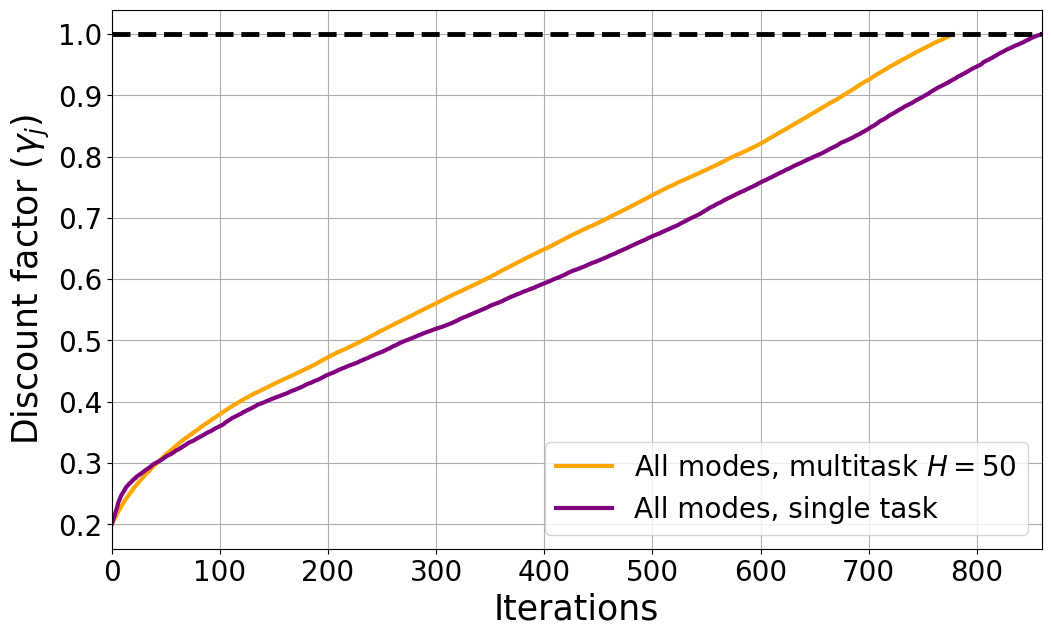

In [11]:
gamma_multitask_H50 = []

for i in range(len(gammas_multitask_H50)):
    if gammas_multitask_H50[i][0]<=1:
        gamma_multitask_H50.append(gammas_multitask_H50[i][0])
        

gamma_singletask = []

for i in range(len(gammas_singletask)):
    if gammas_singletask[i][0] <= 1:
        gamma_singletask.append(gammas_singletask[i][0])

plt.figure(figsize=(12,7)) 
plt.plot(gamma_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(gamma_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(gamma_singletask)), np.ones(len(gamma_singletask)), linestyle='--', color='black', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylabel(r'Discount factor $(\gamma_j)$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

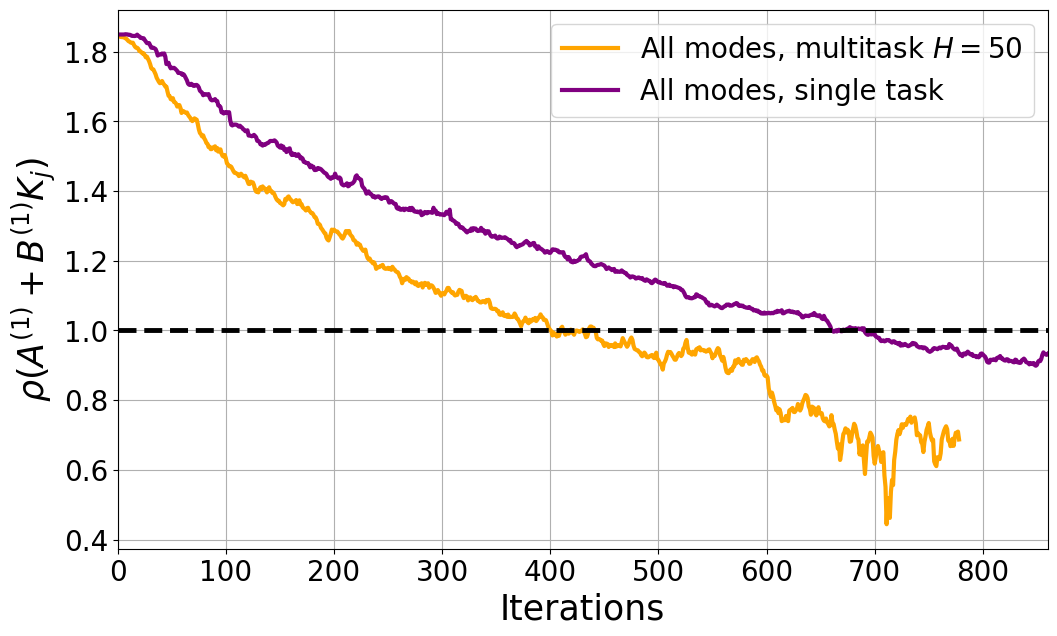

In [12]:
idx = 0

sr_multitask_H50 = []

for i in range(len(srs_multitask_H50)):
    sr_multitask_H50.append(srs_multitask_H50[i][idx])
    

sr_singletask = []

for i in range(len(srs_singletask)):
    sr_singletask.append(srs_singletask[i][0])


plt.figure(figsize=(12,7))
plt.plot(sr_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(sr_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(sr_singletask)), np.ones(len(sr_singletask)), linestyle='--', color='black', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylabel(r'$\rho(A^{(1)}+B^{(1)}K_{j})$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

$\textbf{Learning on a shared subspace:}$

In [14]:
def find_stabilizing_ld(As,Bs,Qs,Rs,gamma,N,r,ns,eta,xi,ns_cost,Phi, As_original, Bs_original):
    
    H = len(As)
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    K = np.zeros((du,dx))
    sr = []
    Sigma_0 = np.eye(dx)
    
    
    gammas = []
    k = 0
    
    gamma_h = [gamma]*H
    sr.append(spectral_radius_mt(As_original,Bs_original,K@Phi.T))
    flag = 0
    
    Ks = [K.copy()]
    while flag == 0:
        
        
        gammas.append(gamma_h.copy())
        
        print(f"Iteration: {k}, Spectral radius: {max(sr[-1])}, gamma: {min(gammas[-1])}")
        K_l = K
        for n in range(N):
            grad_avg = gradient_avg_zo2p(As, Bs, Qs, Rs, K_l, r, ns, gamma_h)
            K_l=K_l - eta*grad_avg
        K = K_l
        
        
        #Update the discount factor
        alphas = []
        gammas_copy = gamma_h.copy()
        gammas_h = gamma_h.copy()
        for h in range(H):
            sigma_min_h = min(abs(la.eigvals(Qs[h] + K.T@Rs[h]@K)))
            alpha_h = sigma_min_h/(2*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma_h[h],ns_cost) - sigma_min_h)
            gammas_h[h] = (1+alpha_h*xi)*gammas_h[h]
            alphas.append(alpha_h)
            

        print("-----")
        print(f"min alpha = {min(alphas)}, avg alpha = {np.mean(alphas)}")
        print("-----")
           
            
        gamma_h_min = [(1+xi*min(alphas))*gamma_h[0]]*H
        gamma_h = gamma_h_min.copy()    
        
        
        Ks.append(K.copy)
        sr.append(spectral_radius_mt(As_original,Bs_original,K@Phi.T))  
        
        if min(gammas_h) >= 1:
            flag = 1
            gammas.append(gamma_h.copy())
            break
        
        k+=1
        
     
    return K, sr, gammas, Ks

$\textbf{Unstable Subspace:}$

In [15]:
def orth_complement(Phi):
    n, l = Phi.shape
    R = np.random.randn(n, n - l)
    R = R - Phi @ (Phi.T @ R)
    Phi_perp = orth(R)
    return Phi_perp

def subspace_distance(Phi1, Phi2):
    P1 = Phi1 @ Phi1.T
    P2 = Phi2 @ Phi2.T
    return norm(P1 - P2, 2)

def orth(A, rtol=1e-12):
    if A.size == 0:
        return A
    Q, R = np.linalg.qr(A)
    diag = np.abs(np.diag(R))
    rank = int(np.sum(diag > rtol * diag.max())) if diag.size else 0
    return Q[:, :rank]

def top_eigenvectors(Proj, l):
    """
    Returns the top l eigenvectors of matrix Proj as columns of Phi.
    """

    eigvals, eigvecs = np.linalg.eig(Proj)

    idx = np.argsort(np.abs(eigvals))[::-1]

    Phi = eigvecs[:, idx[:l]]

    return orth(Phi)

In [16]:
H_tasks = 50

As_tasks = []
Bs_tasks = []
Qs_tasks = []
Rs_tasks = []
for h in range(H_tasks):
    As_tasks.append(As[h])
    Bs_tasks.append(Bs[h])
    Qs_tasks.append(Qs[h])
    Rs_tasks.append(Rs[h])

In [17]:
Phis = []
Proj = np.zeros((d0,d0))
for h in range(H_tasks):
    eigvals_A, eigvecs = np.linalg.eig(As[h].T)
    unstable_idx = np.where(np.abs(eigvals_A) >= 1.0)[0]
    Phis.append(orth(np.real(eigvecs[:, unstable_idx])))
    Proj+=(1/H_tasks)*(Phis[-1]@Phis[-1].T)

$\textbf{Ground-truth shared subspace:}$

In [18]:
Phi_shared = top_eigenvectors(Proj, l)
subspace_distance(Phi_shared, Phis[9])
#math.degrees(math.asin(subspace_distance(Phi_shared, Phis[1])))

np.float64(0.0028773563129775043)

$\textbf{Learning the representation:}$

In [127]:
"""
Adjoint sampling via simulation of the original system, using PyTorch autodiff (backprop).
"""
from __future__ import annotations
import math
from dataclasses import dataclass
from typing import Callable, Optional, Tuple

import torch

Tensor = torch.Tensor


def set_seed(seed: int = 0) -> None:
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def as_vector(x: Tensor) -> Tensor:
    """Ensure 1D tensor."""
    if x.ndim == 1:
        return x
    if x.ndim == 2 and (x.shape[0] == 1 or x.shape[1] == 1):
        return x.view(-1)
    raise ValueError(f"Expected a vector, got shape {tuple(x.shape)}")


# ----------------------------
# Primal rollout
# ----------------------------

@torch.no_grad()
def rollout_primal(
    f: Callable[[Tensor], Tensor],
    x0: Tensor,
    T: int,
) -> Tensor:
    """
    Forward rollout:
        x_{t+1} = f(x_t)
    Returns:
        X: (T+1, d)
    """
    x = as_vector(x0).detach()
    xs = [x]
    for _ in range(T):
        x = as_vector(f(x)).detach()
        xs.append(x)
    return torch.stack(xs, dim=0)

# ----------------------------
# Adjoint sampling via autodiff
# ----------------------------

def vjp_autodiff(
    f: Callable[[Tensor], Tensor],
    x: Tensor,
    v: Tensor,
) -> Tensor:
    """
    Compute J_f(x)^T v using autodiff without forming J_f.

    Implementation:
      g(x) = v^T f(x)
      grad_x g = J_f(x)^T v
    """
    x = as_vector(x).detach().clone().requires_grad_(True)
    v = as_vector(v).detach()

    y = as_vector(f(x))
    g = torch.dot(v, y)

    # Helpful diagnostics
    if not g.requires_grad:
        raise RuntimeError()

    (grad_x,) = torch.autograd.grad(g, x, retain_graph=False, create_graph=False)
    return grad_x.detach()


def rollout_adjoint_from_primal(
    f: Callable[[Tensor], Tensor],
    X: Tensor,
    vT: Tensor,
) -> Tensor:
    if X.ndim != 2:
        raise ValueError("X must be shape (T+1, d)")
    T = X.shape[0] - 1
    d = X.shape[1]

    v = as_vector(vT).detach()
    if v.numel() != d:
        raise ValueError(f"vT has dim {v.numel()} but X has d={d}")

    V = [None] * (T + 1)
    V[T] = v

    for t in reversed(range(T)):
        x_t = X[t]
        v = vjp_autodiff(f, x_t, v)
        V[t] = v

    return torch.stack(V, dim=0)


# ----------------------------
# Simulator
# ----------------------------

def make_linear_f(A: Tensor) -> Callable[[Tensor], Tensor]:
    """f(x) = A x (differentiable; uses torch matmul)."""
    def f(x: Tensor) -> Tensor:
        dx = x.shape[0]
        w = 0.1 * torch.randn(dx, dtype=x.dtype, device=x.device)
        return A @ as_vector(x) + w
    return f

In [128]:
Phis_hat = []
Proj_hat = torch.zeros(d0,d0)

for h in range(H_tasks):

    A = torch.from_numpy(As[h]).to(torch.float32)
    f = make_linear_f(A)

    T = 10 #horizon length
    x0 = torch.randn(d0)
    vT = torch.randn(d0)
    X = rollout_primal(f, x0, T)  # (T+1, d)
    D = rollout_adjoint_from_primal(f, X, vT)
 
    D_arr = np.zeros((d0,T+1))
    for t in range(T+1):
        D_arr[:, t] = D[T - t, :].detach().cpu().numpy()
    
    U, S, Vt = np.linalg.svd(D_arr, full_matrices=False)
    Phi_hat = torch.from_numpy(U[:, :l]).float()
    Phis_hat.append(Phi_hat)

    Proj_hat+=(1/H_tasks)*(Phis_hat[-1]@Phis_hat[-1].T)

In [129]:
Proj_hat =  Proj_hat.numpy()

In [130]:
Phi_shared_hat = top_eigenvectors(Proj_hat, l)
subspace_distance(Phi_shared, Phi_shared_hat)

np.float64(0.0019991293529090437)

In [316]:
def simulate_adj_system(A_task,x,T):
    D = np.zeros((d0,T))
    for t in range(T):
        x = A_task.T @ x
        D[:,t] = x.reshape(d0,)
    return D


x0 = np.random.randn(d0,1)
Proj_hat = np.zeros((d0,d0))
T = 10
for h in range(H_tasks):
    D = simulate_adj_system(As[h],x0,T)
    U,S,V = np.linalg.svd(D)
    Phi_hat = U[:,:l]
    Proj_hat+=(1/H_tasks)*(Phi_hat@Phi_hat.T)
    
Phi_shared_hat = top_eigenvectors(Proj_hat, l)
subspace_distance(Phi_shared, Phi_shared_hat)

np.float64(0.002014821517212319)

$\textbf{Representation estimation error:}$

In [35]:
H = 10

Phis = []
Proj = np.zeros((d0,d0))
for h in range(H):
    eigvals_A, eigvecs = np.linalg.eig(As[h].T)
    unstable_idx = np.where(np.abs(eigvals_A) >= 1.0)[0]
    Phis.append(orth(np.real(eigvecs[:, unstable_idx])))
    Proj+=(1/H)*(Phis[-1]@Phis[-1].T)

Phi_shared = top_eigenvectors(Proj, l)


subspace_dists = []

x0 = torch.randn(d0)
vT = torch.randn(d0)

Ts = list(range(1, 50, 1))

for p in range(len(Ts)):
    
    T = Ts[p]
    Phis_hat = []
    Proj_hat = torch.zeros(d0,d0)
    
    As_tasks = []
    Bs_tasks = []
    Qs_tasks = []
    Rs_tasks = []
    for h in range(H):
        As_tasks.append(As[h])
        Bs_tasks.append(Bs[h])
        Qs_tasks.append(Qs[h])
        Rs_tasks.append(Rs[h])
    

    for h in range(H):

        A = torch.from_numpy(As_tasks[h]).to(torch.float32)
        f = make_linear_f(A)

        
        X = rollout_primal(f, x0, T)  # (T+1, d)
        D = rollout_adjoint_from_primal(f, X, vT)

        D_arr = np.zeros((d0,T+1))
        for t in range(T+1):
            D_arr[:, t] = D[T - t, :].detach().cpu().numpy()

        U, S, Vt = np.linalg.svd(D_arr, full_matrices=False)
        Phi_hat = torch.from_numpy(U[:, :l]).float()
        Phis_hat.append(Phi_hat)

        Proj_hat+=(1/H)*(Phis_hat[-1]@Phis_hat[-1].T)

    Proj_hat =  Proj_hat.numpy()


    Phi_shared_hat = top_eigenvectors(Proj_hat, l)
    subspace_dists.append(subspace_distance(Phi_shared,Phi_shared_hat))

Text(0.5, 0, 'T')

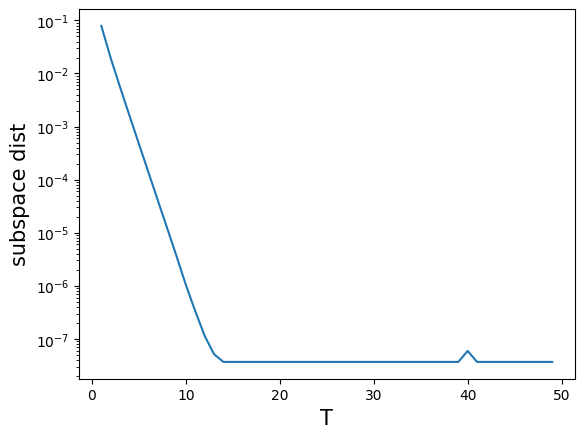

In [36]:
plt.semilogy(Ts,subspace_dists)
plt.ylabel(r'subspace dist',fontsize=15)
plt.xlabel('T',fontsize=15)

In [37]:
Aus = []
Bus = []
Qus = []
Rus = []

for h in range(H_tasks):
    Aus.append(Phi_shared_hat.T@As[h]@Phi_shared_hat)
    Bus.append(Phi_shared_hat.T@Bs[h])
    Qus.append(Phi_shared_hat.T@Qs[h]@Phi_shared_hat)
    Rus.append(Rs[h])

In [38]:
gamma = 0.2
ns = 5
r = 0.1
N = 3
xi = 0.5
ns_cost = 50

Aus_tasks = []
Bus_tasks = []
Qus_tasks = []
Rus_tasks = []
for h in range(H_tasks):
    Aus_tasks.append(Aus[h])
    Bus_tasks.append(Bus[h])
    Qus_tasks.append(Qus[h])
    Rus_tasks.append(Rus[h])

theta, srs_multitask_ld, gammas_multitask_ld,thetas = find_stabilizing_ld(Aus_tasks,Bus_tasks,Qus_tasks,Rus_tasks,gamma,N,r,ns,eta,xi, ns_cost, Phi_shared, As_tasks,Bs_tasks)

Iteration: 0, Spectral radius: 1.8716725687312494, gamma: 0.2
-----
min alpha = 0.10541050576111018, avg alpha = 0.20704253145791043
-----
Iteration: 1, Spectral radius: 1.8713952119806168, gamma: 0.21054105057611106
-----
min alpha = 0.1013075294409735, avg alpha = 0.18434135712351096
-----
Iteration: 2, Spectral radius: 1.8707366433859796, gamma: 0.2212057474159975
-----
min alpha = 0.08831483775123354, avg alpha = 0.15765967042525164
-----
Iteration: 3, Spectral radius: 1.8705143066802887, gamma: 0.2309736222623396
-----
min alpha = 0.06735400945287909, avg alpha = 0.1252256234321599
-----
Iteration: 4, Spectral radius: 1.8701945098078263, gamma: 0.2387521220309513
-----
min alpha = 0.05059425226768897, avg alpha = 0.11778438732216064
-----
Iteration: 5, Spectral radius: 1.869389430700969, gamma: 0.24479186457669128
-----
min alpha = 0.051101698098010524, avg alpha = 0.10438651920391347
-----
Iteration: 6, Spectral radius: 1.868902072350847, gamma: 0.25104650455691485
-----
min alph

-----
min alpha = 0.018550284873331456, avg alpha = 0.04860783453420642
-----
Iteration: 54, Spectral radius: 1.6174343954499264, gamma: 0.3640345695916887
-----
min alpha = 0.018579969037884118, avg alpha = 0.048781683291559554
-----
Iteration: 55, Spectral radius: 1.6166291975370832, gamma: 0.36741644510755517
-----
min alpha = 0.014722664049968397, avg alpha = 0.04830614711031835
-----
Iteration: 56, Spectral radius: 1.6098382331207657, gamma: 0.37012111955143123
-----
min alpha = 0.01690396915632554, avg alpha = 0.04458180759916842
-----
Iteration: 57, Spectral radius: 1.606417116372489, gamma: 0.3732493775459323
-----
min alpha = 0.016720188415176217, avg alpha = 0.04937477121818116
-----
Iteration: 58, Spectral radius: 1.5970966129537443, gamma: 0.3763697775051399
-----
min alpha = 0.022942209081946933, avg alpha = 0.05162908833292941
-----
Iteration: 59, Spectral radius: 1.5852339350104963, gamma: 0.3806871545689643
-----
min alpha = 0.02020431683467526, avg alpha = 0.0474617579

-----
min alpha = 0.037009663849101246, avg alpha = 0.18587429510591436
-----
Iteration: 107, Spectral radius: 1.0213490986823532, gamma: 0.7990020245771594
-----
min alpha = 0.05463616423320814, avg alpha = 0.20079190375927428
-----
Iteration: 108, Spectral radius: 0.9926876922165316, gamma: 0.8208292274958912
-----
min alpha = 0.03493706946084468, avg alpha = 0.19701733000079855
-----
Iteration: 109, Spectral radius: 0.9826811602546265, gamma: 0.8351679113641489
-----
min alpha = 0.045808848564181354, avg alpha = 0.20934492244479463
-----
Iteration: 110, Spectral radius: 0.9688464424095461, gamma: 0.8542969515528208
-----
min alpha = 0.05790522293647559, avg alpha = 0.23585573712098296
-----
Iteration: 111, Spectral radius: 0.9439307454106566, gamma: 0.8790310792696295
-----
min alpha = 0.06087590672502111, avg alpha = 0.226522023068838
-----
Iteration: 112, Spectral radius: 0.9267922239976809, gamma: 0.9057869862646358
-----
min alpha = 0.07683349884023838, avg alpha = 0.25256617356

In [39]:
K_lifted = theta@Phi_shared_hat.T
K_lifted

array([[6.9707925 , 2.07129685]])

In [41]:
H_tasks

50

In [44]:
len(As_tasks)

10

In [46]:
for h in range(H_tasks):
    print(max(abs(la.eigvals(As[h] - Bs[h]@K_lifted))))

0.8013566097852061
0.7285912081153672
0.7908791762753706
0.7229211721637303
0.6686474502255153
0.740655062132044
0.8277551789136987
0.7249174295997893
0.6368482008403042
0.8464639074983162
0.7215271930462746
0.6947933081062874
0.8649116026054632
0.6237545979789254
0.7592530554358755
0.686277585349822
0.7850940019780317
0.831059456989097
0.8250707562259845
0.5558561475655857
0.7678625207301946
0.6639200585782733
0.8099415500895992
0.6417723948688505
0.74655800425544
0.7330485678993645
0.6140674918309058
0.6598844953828132
0.9059885620245164
0.74926659465014
0.9203856060225974
0.8570561884482036
0.6246121360637367
0.814601165090054
0.7191974868595353
0.7870842792259969
0.6330331270116607
0.7875002157748303
0.6757424787873234
0.653121603328239
0.6967636766258889
0.7796748389434691
0.7128298703994453
0.7129391571414306
0.8828851705641547
0.7799040953331682
0.7262641488346281
0.7314388061037322
0.7511819679108365
0.8274415555110957


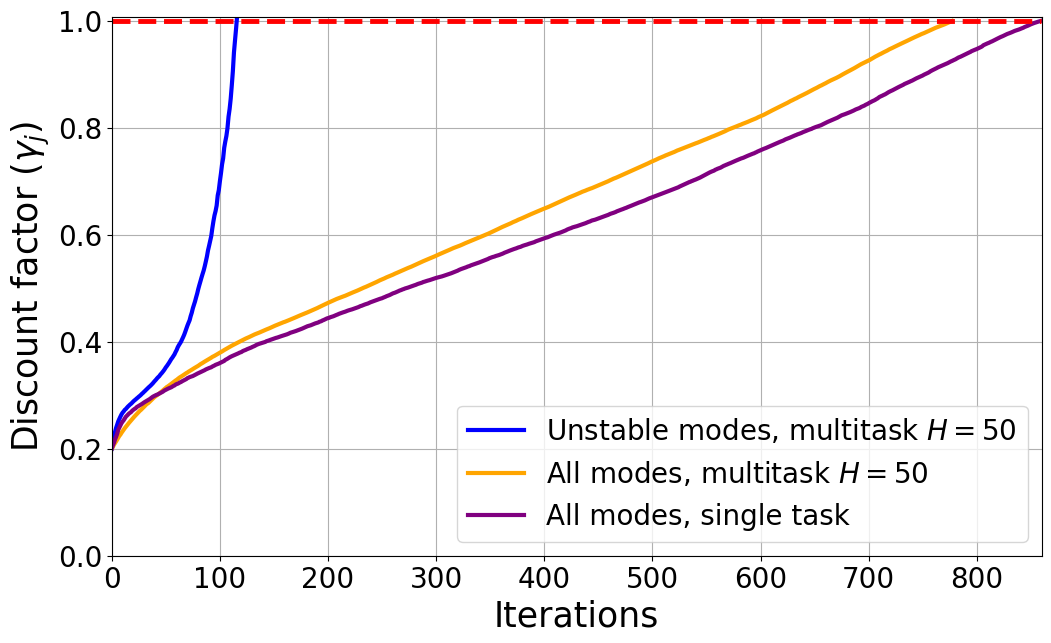

In [42]:
gamma_multitask_ld = []

for i in range(len(gammas_multitask_ld)):
    gamma_multitask_ld.append(gammas_multitask_ld[i][0])
    

plt.figure(figsize=(12,7))
plt.plot(gamma_multitask_ld, color='blue', label=r'Unstable modes, multitask $H = 50$', linewidth=3)
plt.plot(gamma_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(gamma_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(gamma_singletask)), np.ones(len(gamma_singletask)), linestyle='--', color='red', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylim(0, 1+0.75e-2)
plt.ylabel(r'Discount factor $(\gamma_j)$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

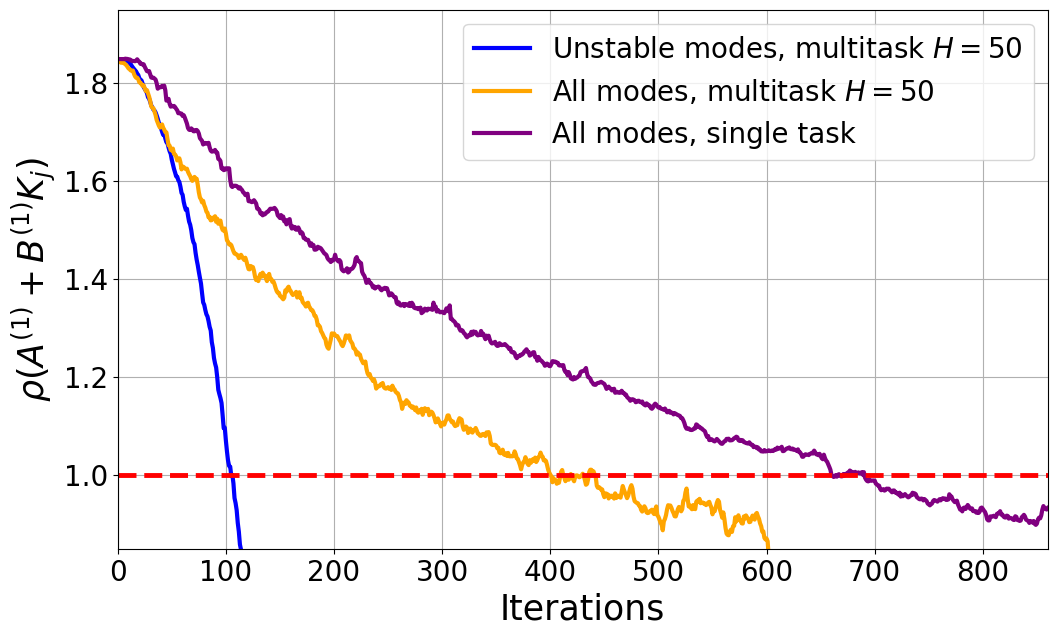

In [43]:
sr_multitask_ld = []

for i in range(len(srs_multitask_ld)):
    sr_multitask_ld.append(srs_multitask_ld[i][0])


plt.figure(figsize=(12,7))
plt.plot(sr_multitask_ld, color='blue', label=r'Unstable modes, multitask $H = 50$', linewidth=3)
plt.plot(sr_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(sr_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(sr_singletask)), np.ones(len(sr_singletask)), linestyle='--', color='red', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylim(0.85, 1.95)
plt.ylabel(r'$\rho(A^{(1)}+B^{(1)}K_{j})$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()